# Classifier mixture posteriors

> Adding stellar mass as a feature makes things a lot more interesting.

The combined model is closer to FLAMINGO near the observed Local Group when stellar
mass is included. Here we compare its full posterior with an equal mixture of the two
specialist posteriors and a mixture whose weight comes from a domain classifier.

This extends the thesis analysis. It tests whether local domain support helps explain
the combined model; it does not yet establish a calibrated inference method for another
simulation. The calculations use the parameter tables in `results/classifier/`.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import truncnorm
from scipy.integrate import trapezoid
from IPython.display import display

# Works from the repository root or from any of its notebook directories.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'pyproject.toml').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook from the repository and follow README.md first.')
DATA = ROOT / 'results' / 'classifier'
parameters = pd.read_csv(DATA / 'posterior_parameters.csv')
archived_quantiles = pd.read_csv(DATA / 'posterior_mixture_quantiles.csv')
archived_distances = pd.read_csv(DATA / 'posterior_mixture_distances.csv')
classifier_validation = pd.DataFrame(json.loads((DATA / 'classifier_validation.json').read_text()))
neighborhoods = pd.read_csv(DATA / 'lg_neighborhoods.csv')

LOWER, UPPER = 11.5, 14.5
GRID = np.linspace(LOWER, UPPER, 6001)
PROBS = np.array([.025, .16, .5, .84, .975])
QUANTILE_COLUMNS = ['q025', 'q16', 'median', 'q84', 'q975']
COLORS = {'flamingo': '#0072B2', 'tng': '#D55E00', 'combined': '#009E73'}
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False})
assert parameters[['family', 'point', 'model']].duplicated().sum() == 0
assert (parameters.sigma > 0).all()
assert parameters.wF_classifier.between(0, 1).all()
display(parameters.loc[parameters.point.eq('LG')].reset_index(drop=True))

,family,point,model,mu,sigma,wF_classifier,common_support
0,dynamics,LG,flamingo,12.472165,0.186436,0.408181,True
1,dynamics,LG,tng,12.508560,0.228681,0.408181,True
2,dynamics,LG,combined,12.507157,0.222945,0.408181,True
3,stellar_sum,LG,flamingo,12.475534,0.134341,0.818941,True
4,stellar_sum,LG,tng,12.749022,0.109227,0.818941,True
5,stellar_sum,LG,combined,12.500056,0.144942,0.818941,True


## What is being mixed?

Let $D$ denote the simulation domain and $\theta=\log_{10}(M_{200c}/M_\odot)$. For a pair of observables $x$, the two specialist posteriors are $q_F(\theta\mid x)$ and $q_T(\theta\mid x)$. The diagnostic reference is

$$q_{\rm mix}(\theta\mid x)=w_F(x)\,q_F(\theta\mid x)
 +[1-w_F(x)]\,q_T(\theta\mid x).$$

We compare $w_F=1/2$ with $w_F(x)=1-p_T(x)$, where the classifier estimates **equal-prior** $p_T(x)=P(D=T\mid x)$. Its class convention is `0 = FLAMINGO`, `1 = TNG300`. Balanced training and calibration correct for the very different catalogue sizes; the raw ratio of nearby pair counts would not do this.

Equal domain training weights define the training joint distribution. They do not require the conditional domain weight at every observed $x$ to equal one half. Under ideal density estimation,

$$P(D=F\mid x)=\frac{p_F(x)}{p_F(x)+p_T(x)}$$

when the two domain priors are equal. In this expression $p_F(x)$ and $p_T(x)$ are feature densities, not classifier class probabilities. Our fitted classifier only approximates the conditional domain weight. **This is a diagnostic probability under a chosen two-simulation population, not evidence that one simulation is the physical truth.**

A mixture of complete posterior densities can have structure that averaging medians or variances discards. It also differs from fitting a single combined network.


## Reconstruct the saved conditional distributions

> For scalar target parameters, the affine MAF reduces to a conditional Gaussian distribution in log-mass space before any explicit support restriction.

The inspected checkpoints have this scalar affine structure. Their saved `mu` and `sigma` therefore specify a Gaussian restricted to $[11.5,14.5]$. We reuse the original diagnostic calculation with `scipy.stats.truncnorm`; we do not assume that an arbitrary flow is Gaussian.

These are **analytic, nominal-input posteriors**. The thesis Local Group tables use finite posterior draws, and separately report an approximate mixture over observational inputs. Small differences from those saved Monte Carlo medians are expected. The classifier mixture below mixes simulations at a fixed nominal input; it does not marginalize the observational uncertainty.


In [2]:
def distributions_at(family, point='LG'):
    """Reuse the archived scalar affine-MAF diagnostic parameterization."""
    rows = parameters.loc[parameters.family.eq(family) & parameters.point.eq(point)]
    assert set(rows.model) == {'flamingo', 'tng', 'combined'}
    assert np.ptp(rows.wF_classifier.to_numpy()) < 1e-12
    distributions = {}
    for row in rows.itertuples():
        a, b = (LOWER - row.mu) / row.sigma, (UPPER - row.mu) / row.sigma
        distributions[row.model] = truncnorm(a, b, loc=row.mu, scale=row.sigma)
    return distributions, float(rows.wF_classifier.iloc[0])


def mixture_values(distributions, weight):
    pdf = weight * distributions['flamingo'].pdf(GRID) + (1 - weight) * distributions['tng'].pdf(GRID)
    cdf = weight * distributions['flamingo'].cdf(GRID) + (1 - weight) * distributions['tng'].cdf(GRID)
    return pdf, cdf


# Match every saved specialist and both pre-specified mixtures, including the
# separation/stellar-mass slices. This also checks the domain-weight convention.
checks = []
for family, point in parameters[['family', 'point']].drop_duplicates().itertuples(index=False, name=None):
    distributions, weight = distributions_at(family, point)
    references = {key: dist.ppf(PROBS) for key, dist in distributions.items()}
    references.update({name: np.interp(PROBS, mixture_values(distributions, w)[1], GRID)
                       for name, w in [('equal_posterior_mixture', .5),
                                       ('classifier_reference_mixture', weight)]})
    for name, quantiles in references.items():
        saved = archived_quantiles.loc[archived_quantiles.family.eq(family)
                                      & archived_quantiles.point.eq(point)
                                      & archived_quantiles.reference.eq(name)]
        assert len(saved) == 1, (family, point, name)
        error = np.max(np.abs(quantiles - saved[QUANTILE_COLUMNS].iloc[0].to_numpy(float)))
        assert error < 2e-7, (family, point, name, error)
        checks.append({'family': family, 'point': point, 'reference': name,
                       'max_quantile_error_dex': error})
print(f'{len(checks)} specialist/mixture quantile reconstructions agree with the saved tables.')
display(pd.DataFrame(checks).groupby('reference').max(numeric_only=True))

40 specialist/mixture quantile reconstructions agree with the saved tables.


,max_quantile_error_dex
reference,
classifier_reference_mixture,3.552714e-15
combined,3.552714e-15
equal_posterior_mixture,3.552714e-15
flamingo,3.552714e-15
tng,1.776357e-15


## Full posteriors at the Local Group

We plot the density and the CDF difference from the combined model. Comparing the full distributions makes the remaining tail differences visible. The point is to assess whether local domain support helps explain the combined model; it does not establish that the combined model equals a literal mixture of its fitted specialists.


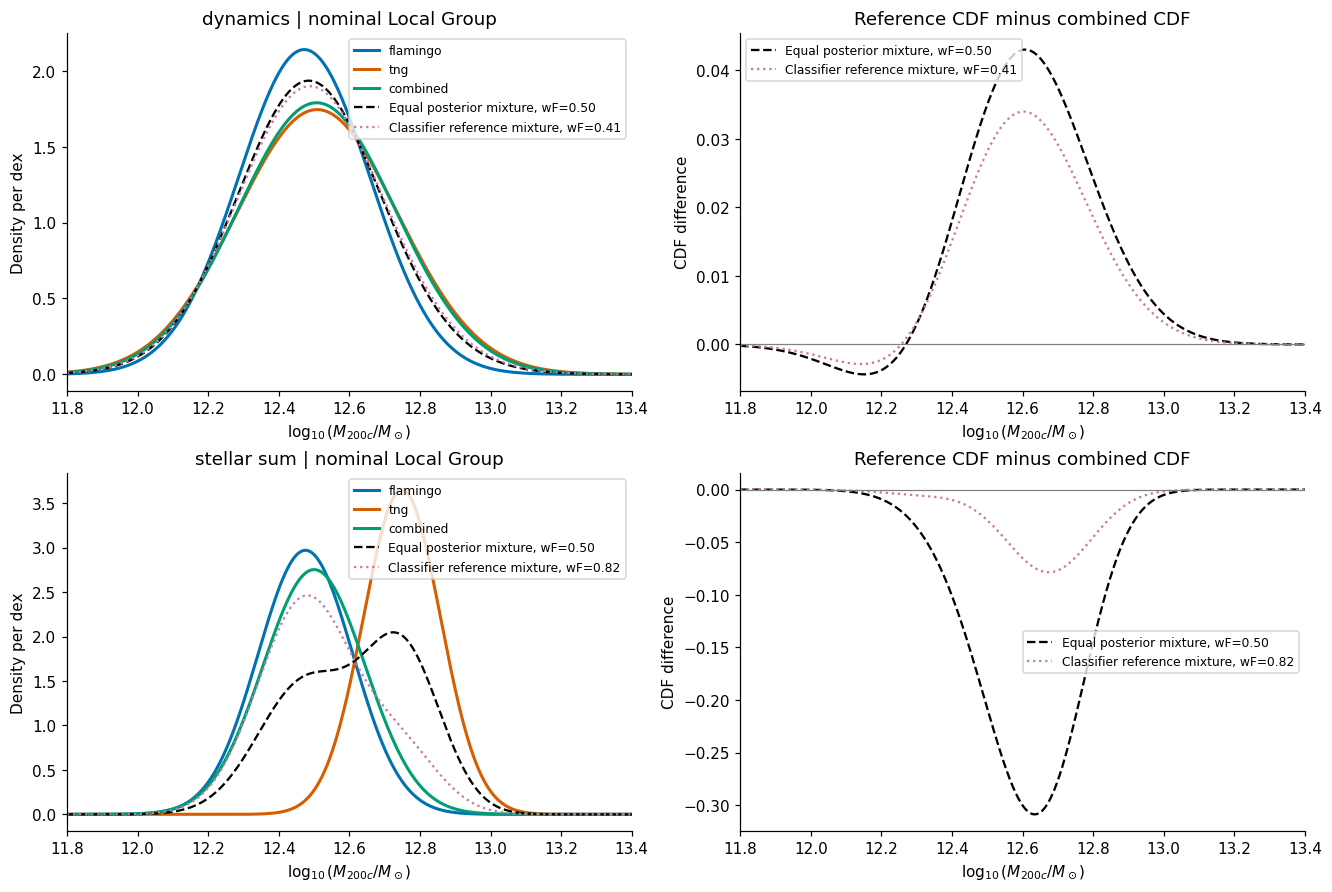

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout='constrained')
for row, family in enumerate(['dynamics', 'stellar_sum']):
    distributions, weight = distributions_at(family)
    ax_pdf, ax_cdf = axes[row]
    for name, dist in distributions.items():
        ax_pdf.plot(GRID, dist.pdf(GRID), color=COLORS[name], label=name, lw=2)
    for name, w, style in [('Equal posterior mixture', .5, '--'),
                           ('Classifier reference mixture', weight, ':')]:
        pdf, cdf = mixture_values(distributions, w)
        label = f'{name}, wF={w:.2f}'
        ax_pdf.plot(GRID, pdf, ls=style, color='black' if w == .5 else '#CC79A7', label=label)
        ax_cdf.plot(GRID, cdf - distributions['combined'].cdf(GRID), ls=style,
                    color='black' if w == .5 else '#CC79A7', label=label)
    ax_pdf.set(title=family.replace('_', ' ') + ' | nominal Local Group', ylabel='Density per dex')
    ax_cdf.axhline(0, color='.5', lw=.8)
    ax_cdf.set(title='Reference CDF minus combined CDF', ylabel='CDF difference')
    for ax in (ax_pdf, ax_cdf):
        ax.set(xlim=(11.8, 13.4), xlabel=r'$\log_{10}(M_{200c}/M_\odot)$')
        ax.legend(fontsize=8)
plt.show()

## Quantify the comparison

For this comparison, the one-dimensional Wasserstein-1 distance is $\int |F-G|\,d\theta$, in dex; Jensen-Shannon divergence is computed by integrating the densities with **natural logarithms**, in nats. This extension's JS values must not be compared directly with the thesis's base-2, KDE-based JSD without accounting for those differences.

The `best_CDF_fit_descriptive` reference optimizes a weight to resemble the combined model. That fitted weight is descriptive only and is not an estimate of domain evidence. The comparison here uses only the equal weight and the independently obtained classifier weight.


In [4]:
distance_rows = []
for family in ['dynamics', 'stellar_sum']:
    distributions, weight = distributions_at(family)
    combined_pdf, combined_cdf = distributions['combined'].pdf(GRID), distributions['combined'].cdf(GRID)
    for reference, w in [('equal_posterior_mixture', .5), ('classifier_reference_mixture', weight)]:
        pdf, cdf = mixture_values(distributions, w)
        mid = (pdf + combined_pdf) / 2
        js = .5 * trapezoid(pdf * np.log(np.maximum(pdf, 1e-300) / np.maximum(mid, 1e-300))
                            + combined_pdf * np.log(np.maximum(combined_pdf, 1e-300)
                                                     / np.maximum(mid, 1e-300)), GRID)
        w1 = trapezoid(np.abs(cdf - combined_cdf), GRID)
        saved = archived_distances.loc[archived_distances.family.eq(family)
                                       & archived_distances.point.eq('LG')
                                       & archived_distances.reference.eq(reference)].iloc[0]
        np.testing.assert_allclose([w1, js], [saved.wasserstein1_dex, saved.JS_nats], atol=2e-9, rtol=1e-7)
        assert abs(trapezoid(pdf, GRID) - 1) < 1e-6
        distance_rows.append(dict(family=family, reference=reference, wF=w,
                                  wasserstein1_dex=w1, JS_nats=js))
distances = pd.DataFrame(distance_rows)
display(distances)
display(archived_quantiles.loc[archived_quantiles.point.eq('LG')
                              & ~archived_quantiles.reference.eq('best_CDF_fit_descriptive')]
        .reset_index(drop=True))

,family,reference,wF,wasserstein1_dex,JS_nats
0,dynamics,equal_posterior_mixture,0.500000,0.018919,0.001814
1,dynamics,classifier_reference_mixture,0.408181,0.014793,0.001056
2,stellar_sum,equal_posterior_mixture,0.500000,0.112222,0.072653
3,stellar_sum,classifier_reference_mixture,0.818941,0.024996,0.009918


,family,point,reference,q025,q16,median,q84,q975
0,dynamics,LG,flamingo,12.106757,12.286762,12.472165,12.657568,12.837573
1,dynamics,LG,tng,12.060374,12.281151,12.508562,12.735974,12.956766
2,dynamics,LG,combined,12.070205,12.285451,12.507158,12.728867,12.944121
3,dynamics,LG,equal_posterior_mixture,12.083366,12.284223,12.488511,12.696508,12.908086
4,dynamics,LG,classifier_reference_mixture,12.079068,12.283703,12.491891,12.703848,12.918547
5,stellar_sum,LG,flamingo,12.212230,12.341938,12.475534,12.609131,12.738838
6,stellar_sum,LG,tng,12.534942,12.640401,12.749022,12.857644,12.963103
7,stellar_sum,LG,combined,12.215975,12.355917,12.500056,12.644195,12.784138
8,stellar_sum,LG,equal_posterior_mixture,12.254559,12.412317,12.626378,12.802405,12.929075
9,stellar_sum,LG,classifier_reference_mixture,12.223899,12.360215,12.512087,12.700575,12.871616


For stellar mass, the classifier reference is closer to the combined posterior than the equal posterior mixture in this comparison. The CDF plot still shows a difference in the upper tail. Specialist error, the uncertainty in the domain weight, and finite training effects remain entangled. A conditional Gaussian fit cannot represent every possible mixture shape.

## Check the classifier before interpreting its weight

The diagnostic classifier was trained on the training rows. A logistic calibrator was fitted to the validation rows, using balanced class weights; the test rows were retained for reporting. There are 130 TNG300 validation pairs and 231 TNG300 test pairs. The reliability plots assess global balanced calibration, which is not a precise local validation of the Local Group weight.


,family,auc,brier,log_loss,ece10,wF_LG,n_validation_tng,n_test_tng
0,dynamics,0.643013,0.233275,0.659109,0.063139,0.408181,130,231
1,stellar_sum,0.830925,0.167373,0.507551,0.025652,0.818941,130,231


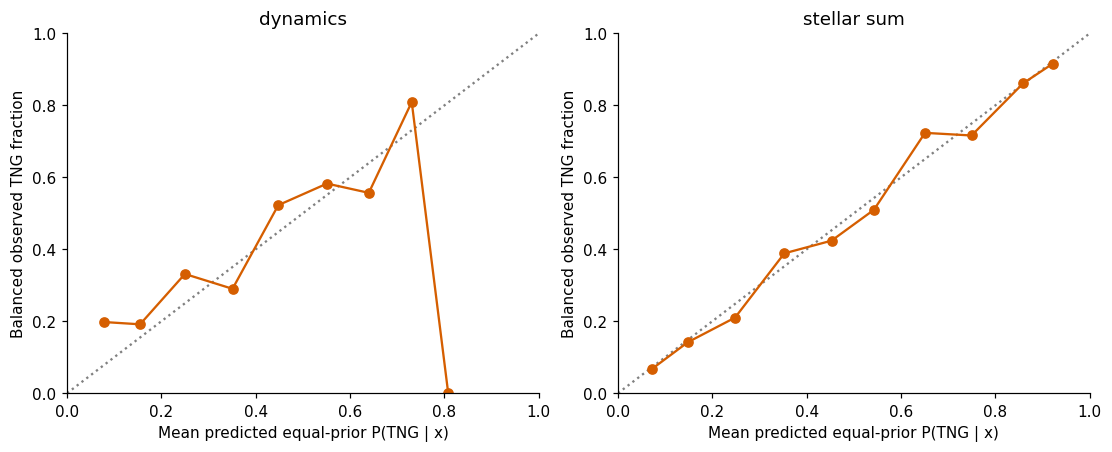

In [5]:
display(classifier_validation[['family', 'auc', 'brier', 'log_loss', 'ece10', 'wF_LG',
                               'n_validation_tng', 'n_test_tng']])
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout='constrained')
for ax, family in zip(axes, ['dynamics', 'stellar_sum']):
    reliability = pd.read_csv(DATA / f'classifier_reliability_{family}.csv')
    ax.plot([0, 1], [0, 1], ':', color='.5')
    ax.plot(reliability.pred, reliability.observed, 'o-', color=COLORS['tng'])
    ax.set(title=family.replace('_', ' '), xlabel='Mean predicted equal-prior P(TNG | x)',
           ylabel='Balanced observed TNG fraction', xlim=(0, 1), ylim=(0, 1))
plt.show()

## Does the local catalogue tell the same story?

For a ball of radius $r$ in the equal-domain standardized feature space, we normalize each domain's count by its total training count:

$$\widehat w_F(r)=\frac{n_F(r)/N_F}{n_F(r)/N_F+n_T(r)/N_T}.$$

The neighbourhood calculations use the same training populations. Their radius sensitivity is a diagnostic, not a confidence interval for the classifier weight. Sparse TNG300 neighborhoods also limit how strongly we can interpret the local estimate.


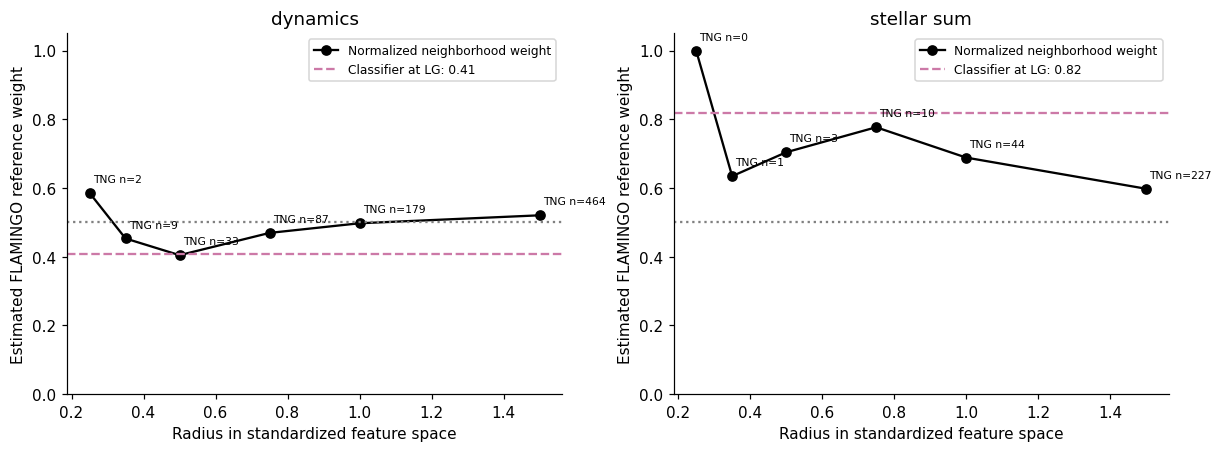

,family,domain,host,n,independent_components,same_host_fraction
0,dynamics,flamingo,pooled,2093,2088,0.493072
1,dynamics,flamingo,same_host,1032,1032,1.000000
2,dynamics,flamingo,different_host,1061,1058,0.000000
3,dynamics,tng,pooled,33,33,1.000000
4,dynamics,tng,same_host,33,33,1.000000
5,dynamics,tng,different_host,0,0,NaN
6,stellar_sum,flamingo,pooled,666,665,0.513514
7,stellar_sum,flamingo,same_host,342,342,1.000000
8,stellar_sum,flamingo,different_host,324,323,0.000000
9,stellar_sum,tng,pooled,3,3,1.000000


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
for ax, family in zip(axes, ['dynamics', 'stellar_sum']):
    local = neighborhoods.loc[neighborhoods.family.eq(family) & neighborhoods.host.eq('pooled')]
    f = local.loc[local.domain.eq('flamingo')].set_index('radius')
    t = local.loc[local.domain.eq('tng')].set_index('radius')
    normalized_f = f.n / f.n_training
    normalized_t = t.n / t.n_training
    reconstructed = normalized_f / (normalized_f + normalized_t)
    np.testing.assert_allclose(reconstructed, f.wF_equal_domain_ball, atol=1e-12)
    ax.plot(f.index, reconstructed, 'o-', color='black', label='Normalized neighborhood weight')
    weight = classifier_validation.set_index('family').loc[family, 'wF_LG']
    ax.axhline(weight, ls='--', color='#CC79A7', label=f'Classifier at LG: {weight:.2f}')
    ax.axhline(.5, ls=':', color='.5')
    for radius in f.index:
        ax.annotate(f'TNG n={int(t.loc[radius, "n"])}', (radius, reconstructed.loc[radius]),
                    xytext=(2, 7), textcoords='offset points', fontsize=7)
    ax.set(title=family.replace('_', ' '), xlabel='Radius in standardized feature space',
           ylabel='Estimated FLAMINGO reference weight', ylim=(0, 1.05))
    ax.legend(fontsize=8)
plt.show()

# Host composition at one illustrative radius; the full radius table remains visible.
display(neighborhoods.loc[neighborhoods.radius.eq(.5)]
        [['family', 'domain', 'host', 'n', 'independent_components', 'same_host_fraction']]
        .reset_index(drop=True))

The networks are fitted to mixed host systems without a host indicator. Same-host pairs use one host's $M_{200c}$, whereas different-host pairs sum the two host masses. The observed Milky Way-M31 system is a different-host configuration. A pooled neighborhood or classifier can therefore indicate feature support while offering little support for the intended host configuration. This limitation carries into both specialist and mixture posteriors.

## Vary the weight without changing the observations

This last calculation shows the dependence on the assumed mixture weight. It is a sensitivity curve; the horizontal axis is not a posterior distribution over weights. The classifier's weight is one diagnostic estimate on that curve.


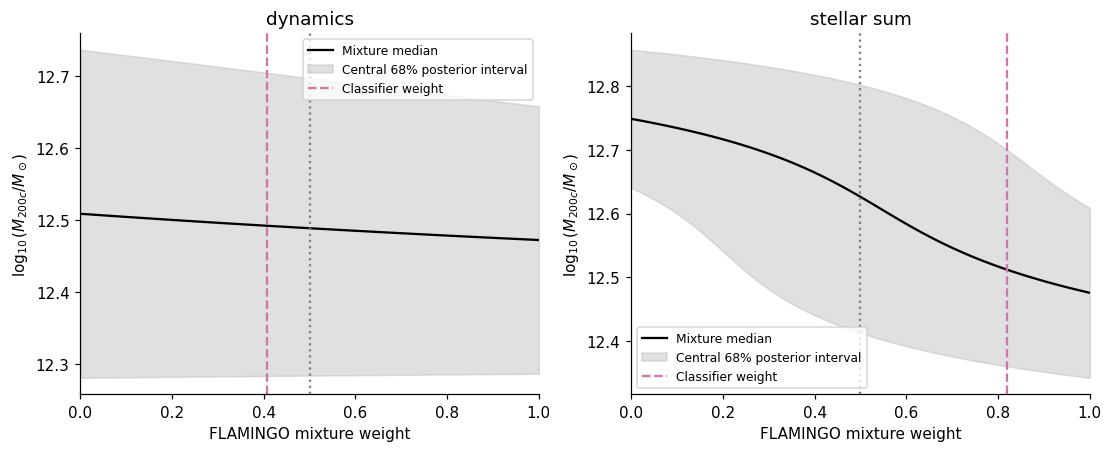

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout='constrained')
weights = np.linspace(0, 1, 101)
for ax, family in zip(axes, ['dynamics', 'stellar_sum']):
    distributions, classifier_weight = distributions_at(family)
    intervals = np.array([np.interp([.16, .5, .84], mixture_values(distributions, w)[1], GRID)
                          for w in weights])
    ax.plot(weights, intervals[:, 1], color='black', label='Mixture median')
    ax.fill_between(weights, intervals[:, 0], intervals[:, 2], color='.7', alpha=.4,
                    label='Central 68% posterior interval')
    ax.axvline(classifier_weight, ls='--', color='#CC79A7', label='Classifier weight')
    ax.axvline(.5, ls=':', color='.5')
    ax.set(title=family.replace('_', ' '), xlabel='FLAMINGO mixture weight',
           ylabel=r'$\log_{10}(M_{200c}/M_\odot)$', xlim=(0, 1))
    ax.legend(fontsize=8)
plt.show()

## Further tests

> However, no evidence is provided as to which simulation represents the underlying truth or a unique physical cause for the transfer failure.

The reference mixture helps describe the relationship between the specialist and combined
posteriors. Establishing its calibration as an inference method needs further experiments:

1. Repeat specialist and combined fits across seeds to measure retraining variability.
2. Compare full posterior shapes and calibration with a flexible scalar density, such as an NSF or MDN, using the same feature sets.
3. Fit a host-conditioned or different-host model with a consistent target, and assess the limited TNG300 sample.
4. Test mixture calibration on held-out pairs, propagate classifier-weight uncertainty, and check local support at the observation.
5. Assess transfer to another simulation and align simulated and observational stellar-mass definitions.

### Implementation

The reconstruction uses the saved Gaussian parameters, a 6,001-point grid, and the
same truncated-density and distance calculations used for the specialist comparison.
Classifier and neighbourhood tables supply the domain weights. The source records in
notebook metadata identify the calculation. No checkpoint loading is needed to run it.
